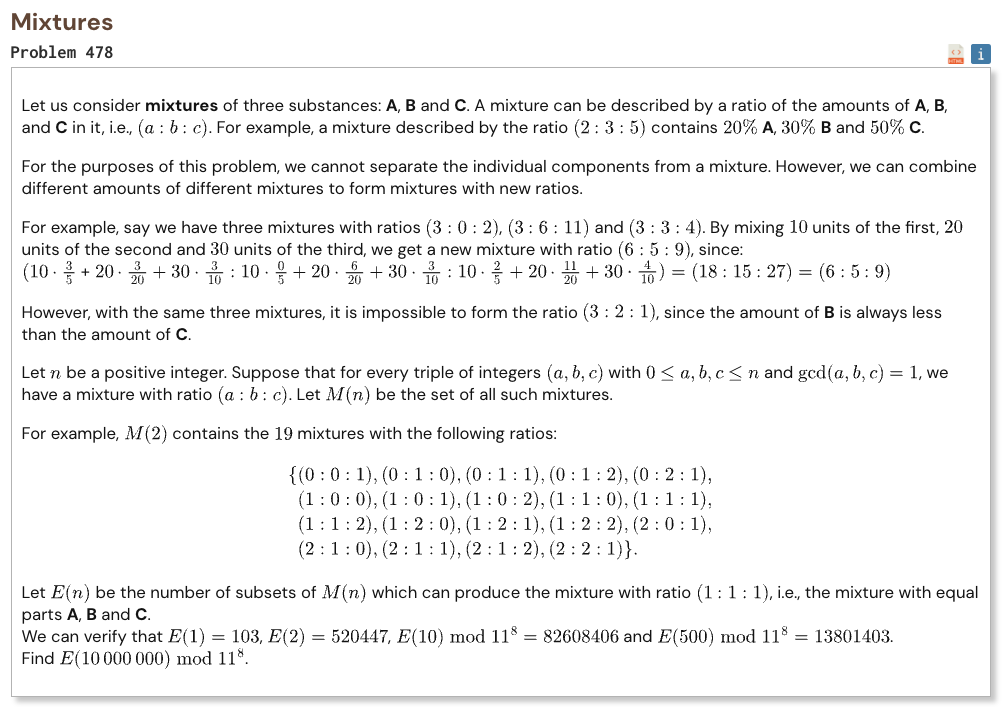

## Initial approach

- represent each mixture by how far its three components are from being equal
- a subset can make equal parts exactly when its direction vectors surround the origin
- count all primitive triples with Möbius inversion instead of generating the mixtures one by one
- use Euler totients to count the primitive boundary directions that create the bad subsets
- for each boundary direction count the primitive lattice points lying on one side of it
- reduce the huge powers of two modulo the totient of 11^8
- use numpy for compact arrays and numba because the main summation has about n log n iterations
- combine the total subsets and the bad subsets and return the answer modulo 11^8

In [1]:
%%time

import numpy as np
from numba import njit

N = 10_000_000
MOD = 11**8
PHI = 10 * 11**7
PHI2 = 2 * PHI

@njit
def build_mu_phi(n):
    mu = np.zeros(n + 1, dtype=np.int8)
    phi = np.zeros(n + 1, dtype=np.int32)
    primes = np.empty(n // 2 + 1, dtype=np.int32)

    mu[1] = 1
    phi[1] = 1
    prime_count = 0

    for i in range(2, n + 1):
        if phi[i] == 0:
            primes[prime_count] = i
            prime_count += 1
            mu[i] = -1
            phi[i] = i - 1

        for j in range(prime_count):
            p = primes[j]
            v = i * p

            if v > n:
                break

            if i % p == 0:
                mu[v] = 0
                phi[v] = phi[i] * p
                break

            mu[v] = -mu[i]
            phi[v] = phi[i] * (p - 1)

    return mu, phi

@njit
def pow2_mod(exp):
    result = 1
    base = 2

    while exp > 0:
        if exp & 1:
            result = result * base % MOD

        base = base * base % MOD
        exp >>= 1

    return result

@njit
def primitive_count_mod(n, mu):
    total = 0
    mertens = 0

    for d in range(1, n + 1):
        m = mu[d]

        if m == 0:
            continue

        q = n // d
        x = (q + 1) % PHI2

        cube = x * x % PHI2
        cube = cube * x % PHI2

        total = (total + m * cube) % PHI2
        mertens = (mertens + m) % PHI2

    return (total - mertens) % PHI2

@njit
def solve(n):
    mu, phi = build_mu_phi(n)

    primitive_mod2phi = primitive_count_mod(n, mu)
    primitive_mod_phi = primitive_mod2phi % PHI

    half_exp = ((primitive_mod2phi - 1) % PHI2) // 2
    half_exp %= PHI

    phi_sum = 0

    for i in range(1, n + 1):
        phi_sum += phi[i]

        if phi_sum >= MOD:
            phi_sum %= MOD

    boundary = 6 * phi_sum % MOD

    correction_sum = 0

    for L in range(1, n + 1):
        m = n // L
        inner = 1

        for d in range(1, m + 1):
            md = mu[d]

            if md == 0:
                continue

            q = m // d
            nd = n // d

            term = (
                q * nd
                - L * q * (q + 1) // 2
            )

            inner += md * term

        exponent = (
            half_exp - inner % PHI
        ) % PHI

        contribution = (
            6
            * int(phi[L])
            * pow2_mod(exponent)
        ) % MOD

        correction_sum += contribution

        if correction_sum >= MOD:
            correction_sum %= MOD

    bad = (
        1
        + pow2_mod(half_exp) * boundary
        - correction_sum
    ) % MOD

    result = (
        pow2_mod(primitive_mod_phi)
        - bad
    ) % MOD

    return result

result = solve(N)

print("Result:", result)

Result: 59510340
CPU times: user 2 s, sys: 169 ms, total: 2.17 s
Wall time: 2.81 s
